<a href="https://colab.research.google.com/github/k1-r1ll/pytorch/blob/main/pytorch6_collab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 31:00

In [ ]:
# Ячейка 1: Базовые библиотеки
import torch                      # Основной фреймворк глубокого обучения PyTorch
import matplotlib.pyplot as plt # Библиотека для построения графиков и отрисовки картинок

# Ячейка 2: Инструменты для работы с изображениями и датасетами
import torchvision.transforms.v2 as T           # Современный модуль преобразований изображений (v2)
from torchvision.datasets import OxfordIIITPet  # Встроенный класс для загрузки датасета питомцев

# Скачиваем датасет в локальную папку '../datasets/pets' и указываем, что нам нужна разметка для сегментации
# (Этот вызов нужен один раз, чтобы скачать архивы на диск перед созданием train_dataset и valid_dataset)
dataset = OxfordIIITPet('../datasets/pets', target_types='segmentation', download=True)

100%|██████████| 792M/792M [00:37<00:00, 20.8MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.3MB/s]


In [ ]:
# Пайплайн преобразований для входных изображений (фотографий питомцев)
transform = T.Compose(
    [
        T.Resize((128, 128)),  # Приводим все фото к единому размеру 128x128 пикселей
        T.ToTensor(),          # Переводим картинку в тензор PyTorch и нормализуем пиксели в диапазон [0.0, 1.0]
    ]
)

# Пайплайн преобразований для целевых масок сегментации (разметки)
target_transform = T.Compose(
    [
        T.Resize((128, 128)),  # Сжимаем маску до того же размера 128x128, что и исходное фото
        T.PILToTensor(),       # Переводим маску в тензор, сохраняя исходные целые числа (без деления на 255)
        # Сдвигаем номера классов с [1, 2, 3] на [0, 1, 2] для функции потерь (например, CrossEntropyLoss)
        # и приводим тип данных к int64 (.long())
        T.Lambda(lambda x: (x - 1).long())
    ]
)

# Загружаем обучающую выборку (по умолчанию split='trainval')
train_dataset = OxfordIIITPet(
    '../datasets/pets',                # Путь к локальной папке с датасетом
    transform=transform,               # Применяем преобразования к фото
    target_transform=target_transform, # Применяем преобразования к маскам
    target_types='segmentation'        # Указываем, что нам нужны именно маски сегментации, а не просто породы
)

# Загружаем тестовую выборку (будет использоваться для валидации)
valid_dataset = OxfordIIITPet(
    '../datasets/pets',
    transform=transform,
    split='test',                      # Явно берем тестовую часть датасета
    target_transform=target_transform,
    target_types='segmentation'
)

# Импортируем класс для удобной подачи данных в нейросеть пакетами (батчами)
from torch.utils.data import DataLoader

# Создаем загрузчик для обучения
train_loader = DataLoader(
    train_dataset,
    batch_size=64, # Модель будет обрабатывать по 64 картинки за один шаг
    shuffle=True,  # Перемешиваем данные перед каждой эпохой, чтобы модель не запоминала порядок
    num_workers=8  # Используем 8 потоков процессора для ускорения загрузки картинок с диска
)

# Создаем загрузчик для валидации
valid_loader = DataLoader(
    valid_dataset,
    batch_size=64,
    shuffle=False, # При проверке качества перемешивать данные не нужно
    num_workers=8
)


/usr/local/lib/python3.13/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.optim import Optimizer
from tqdm import tqdm

# Функция для проведения одной эпохи обучения модели
def train(model: nn.Module, data_loader: DataLoader, optimizer: Optimizer, loss_fn, device: torch.device):
    # Переводим модель в режим обучения (включаются Dropout, BatchNorm и др.)
    model.train()

    # Переменные для подсчета статистики за всю эпоху
    total_loss = 0  # Сумма значений функции потерь (ошибки) по всем батчам
    total = 0       # Общее количество проверенных пикселей
    correct = 0     # Количество правильно классифицированных пикселей

    # Проходим по всем батчам из загрузчика, tqdm рисует полосу прогресса (progress bar)
    for x, y in tqdm(data_loader):
        bs = y.size(0)  # Размер текущего батча (количество картинок; в коде далее не используется)

        # Переносим входные фото (x) и маски (y) на нужное устройство (видеокарту GPU или CPU)
        # squeeze(1) убирает лишнюю размерность канала у маски: из [Batch, 1, 128, 128] делает [Batch, 128, 128]
        x, y = x.to(device), y.squeeze(1).to(device)

        # Обнуляем градиенты с предыдущего шага, чтобы они не накапливались
        optimizer.zero_grad()

        # Прямой проход (forward pass): модель делает предсказание для батча картинок
        output = model(x)

        # Считаем ошибку (loss) между предсказанием модели и реальной маской
        loss = loss_fn(output, y)

        # Обратное распространение ошибки (backward pass): вычисляем градиенты для всех весов
        loss.backward()

        # Прибавляем значение ошибки текущего батча к общей сумме (.item() извлекает обычное число из тензора)
        total_loss += loss.item()

        # Получаем предсказанный класс для каждого пикселя (находим индекс максимального значения по оси классов dim=1)
        _, y_pred = output.max(dim=1)

        # Увеличиваем счетчик общего числа пикселей (батч * высота * ширина)
        total += y.size(0) * y.size(1) * y.size(2)

        # Считаем, сколько пикселей модель угадала верно, и добавляем к общему счетчику
        correct += (y == y_pred).sum().item()

        # Шаг оптимизатора: обновляем веса нейросети на основе вычисленных градиентов
        optimizer.step()

    # Возвращаем среднюю ошибку за эпоху и общую точность (pixel accuracy)
    return total_loss / len(data_loader), correct / total


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm

# Декоратор отключает вычисление градиентов, ускоряя проверку и экономя видеопамять
@torch.inference_mode()
def evaluate(model: nn.Module, data_loader: DataLoader, loss_fn, device: torch.device):
    # Переводим модель в режим оценки (отключаем Dropout, фиксируем статистики BatchNorm)
    model.eval()

    # Счетчики для накопления статистики за весь проход по валидации
    total_loss = 0  # Сумма ошибок по всем батчам
    total = 0       # Общее количество проверенных пикселей
    correct = 0     # Количество правильно угаданных пикселей

    # Проходим по всем батчам валидационного загрузчика
    for x, y in tqdm(data_loader):
        bs = y.size(0)  # Размер текущего батча (далее в функции не используется)

        # Переносим картинки и маски на GPU/CPU, убирая лишнюю размерность канала у маски
        x, y = x.to(device), y.squeeze(1).to(device)

        # Прямой проход: получаем предсказания модели
        output = model(x)

        # Вычисляем значение функции потерь на текущем батче
        loss = loss_fn(output, y)

        # Прибавляем ошибку батча к общей сумме
        total_loss += loss.item()

        # Находим индекс класса с максимальным значением для каждого пикселя
        _, y_pred = output.max(dim=1)

        # Считаем общее число пикселей и количество совпадений с истинной маской
        total += y.size(0) * y.size(1) * y.size(2)
        correct += (y == y_pred).sum().item()

    # Возвращаем среднюю ошибку и попиксельную точность (Pixel Accuracy)
    return total_loss / len(data_loader), correct / total

In [ ]:
# import torchvision.transforms as T
# from torchvision.datasets import OxfordIIITPet
# from torch.utils.data import DataLoader

# # Преобразования для входных фотографий
# transform = T.Compose(
#     [
#         T.Resize((128, 128)),  # Стандартная билинейная интерполяция отлично подходит для фото
#         T.ToTensor(),          # Переводим в тензор и масштабируем значения пикселей в [0.0, 1.0]
#     ]
# )

# # Преобразования для масок сегментации
# target_transform = T.Compose(
#     [
#         # Используем NEAREST (метод ближайшего соседа), чтобы при сжатии не появлялись
#         # несуществующие дробные классы на границах объектов
#         T.Resize((128, 128), interpolation=T.InterpolationMode.NEAREST),
#         T.PILToTensor(),
#         # Сдвигаем метки классов из [1, 2, 3] в [0, 1, 2] и переводим в int64
#         T.Lambda(lambda x: (x - 1).long())
#     ]
# )

# train_dataset = OxfordIIITPet(
#     '../datasets/pets',
#     transform=transform,
#     target_transform=target_transform,
#     target_types='segmentation'
# )

# valid_dataset = OxfordIIITPet(
#     '../datasets/pets',
#     transform=transform,
#     split='test',
#     target_transform=target_transform,
#     target_types='segmentation'
# )

# train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=8)
# valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False, num_workers=8)


In [ ]:
# import torch
# import torch.nn as nn
# from torch.utils.data import DataLoader
# from torch.optim import Optimizer
# from tqdm import tqdm

# # Добавили параметр num_classes=3 (в датасете OxfordIIITPet три класса: питомец, фон и контур)
# def train(model: nn.Module, data_loader: DataLoader, optimizer: Optimizer, loss_fn, device: torch.device, num_classes: int = 3):
#     model.train()

#     total_loss = 0.0
#     total_pixels = 0
#     correct_pixels = 0

#     # Тензоры для накопления пересечений и объединений по каждому классу (для расчета IoU)
#     intersection = torch.zeros(num_classes, device=device)
#     union = torch.zeros(num_classes, device=device)

#     for x, y in tqdm(data_loader):
#         x, y = x.to(device), y.squeeze(1).to(device)

#         optimizer.zero_grad()
#         output = model(x)
#         loss = loss_fn(output, y)
#         loss.backward()
#         optimizer.step()

#         # Умножаем ошибку батча на его реальный размер x.size(0), чтобы корректно учесть последний неполный батч
#         total_loss += loss.item() * x.size(0)

#         # Получаем предсказанные классы для каждого пикселя
#         _, y_pred = output.max(dim=1)

#         # Считаем попиксельную точность (Pixel Accuracy)
#         total_pixels += y.numel()  # .numel() возвращает общее число элементов в тензоре (B * H * W)
#         correct_pixels += (y == y_pred).sum().item()

#         # Накапливаем статистику для метрики IoU по каждому классу
#         for cls in range(num_classes):
#             pred_mask = (y_pred == cls)
#             target_mask = (y == cls)
#             intersection[cls] += (pred_mask & target_mask).sum()
#             union[cls] += (pred_mask | target_mask).sum()

#     # Вычисляем итоговые метрики за эпоху
#     avg_loss = total_loss / len(data_loader.dataset)
#     pixel_acc = correct_pixels / total_pixels
#     # Добавляем 1e-6 в знаменатель для защиты от деления на ноль
#     mean_iou = (intersection / (union + 1e-6)).mean().item()

#     return avg_loss, pixel_acc, mean_iou


In [ ]:
# Что именно улучшилось

# • Защита границ маски. Параметр interpolation=T.InterpolationMode.NEAREST запрещает усреднять соседние пиксели при сжатии.
# Это гарантирует, что в маске останутся только целые номера классов.
# • Точный подсчет ошибки. Умножение loss.item() на размер текущего батча x.size(0) и деление на len(data_loader.dataset) устраняет перекос,
# если общее число картинок не делится на 64 без остатка.
# • Чистота кода. Удалена неиспользуемая переменная bs, а громоздкое умножение размерностей заменено на встроенный метод y.numel().
# • Объективная оценка качества. Функция теперь возвращает Mean IoU (среднее пересечение над объединением),
# которая честно оценивает качество сегментации даже при сильном перевесе пикселей фона.
# Хотите, я напишу парную функцию evaluate для валидации модели с теми же метриками или помогу собрать полный цикл обучения на несколько эпох с сохранением лучших весов?

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Устанавливаем стиль оформления графиков (темная сетка на фоне)
sns.set(style='darkgrid')

# Функция для отрисовки графиков обучения и валидации
def plot_stats(
    train_loss: list[float],      # Список значений ошибки на обучении по эпохам
    valid_loss: list[float],      # Список значений ошибки на валидации по эпохам
    train_accuracy: list[float],  # Список значений точности на обучении
    valid_accuracy: list[float],  # Список значений точности на валидации
    title: str                    # Общий заголовок (например, название модели)
):
    # --- Первый график: функция потерь (Loss) ---
    plt.figure(figsize=(16, 8))               # Задаем размер холста (16x8 дюймов)
    plt.title(title + ' loss')                # Заголовок графика

    plt.plot(train_loss, label='Train loss')  # Кривая ошибки на обучении
    plt.plot(valid_loss, label='Valid loss')  # Кривая ошибки на валидации
    plt.legend()                              # Отображаем легенду с подписями линий

    plt.show()                                # Выводим первый график на экран

    # --- Второй график: точность (Accuracy) ---
    plt.figure(figsize=(16, 8))               # Создаем новый холст такого же размера
    plt.title(title + ' accuracy')            # Заголовок второго графика

    plt.plot(train_accuracy, label='Train accuracy')  # Кривая точности на обучении
    plt.plot(valid_accuracy, label='Valid accuracy')  # Кривая точности на валидации
    plt.legend()                                      # Отображаем легенду

    plt.show()                                        # Выводим второй график на экран


In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# sns.set(style='darkgrid')

# def plot_stats(
#     train_loss: list[float],
#     valid_loss: list[float],
#     train_acc: list[float],
#     valid_acc: list[float],
#     train_iou: list[float],
#     valid_iou: list[float],
#     title: str
# ):
#     # Создаем сетку из 1 строки и 3 столбцов для компактного отображения рядом
#     fig, axes = plt.subplots(1, 3, figsize=(20, 5))
#     fig.suptitle(title, fontsize=16)

#     # 1. График ошибки (Loss)
#     axes[0].plot(train_loss, label='Train')
#     axes[0].plot(valid_loss, label='Valid')
#     axes[0].set_title('Loss')
#     axes[0].set_xlabel('Epoch')
#     axes[0].legend()

#     # 2. График попиксельной точности (Accuracy)
#     axes[1].plot(train_acc, label='Train')
#     axes[1].plot(valid_acc, label='Valid')
#     axes[1].set_title('Pixel Accuracy')
#     axes[1].set_xlabel('Epoch')
#     axes[1].legend()

#     # 3. График качества сегментации (Mean IoU)
#     axes[2].plot(train_iou, label='Train')
#     axes[2].plot(valid_iou, label='Valid')
#     axes[2].set_title('Mean IoU')
#     axes[2].set_xlabel('Epoch')
#     axes[2].legend()

#     plt.tight_layout()  # Автоматически выравниваем отступы, чтобы подписи не наезжали друг на друга
#     plt.show()


In [ ]:
import numpy as np
from PIL import Image

# Декоратор отключает расчет градиентов для ускорения работы и экономии памяти (аналог torch.no_grad())
@torch.inference_mode()
def visualize(model, batch, device):
    # Переводим модель в режим оценки (отключаем Dropout, фиксируем BatchNorm)
    model.eval()

    # Распаковываем батч на входные картинки (xs) и целевые маски (ys)
    xs, ys = batch

    # Преобразователь тензора PyTorch обратно в формат картинки PIL для отрисовки
    to_pil = T.ToPILImage()

    # Перебираем пары (картинка, маска) из батча с их порядковым номером i
    for i, (x, y) in enumerate(zip(xs, ys)):
        # Добавляем размерность батча (.unsqueeze(0)), прогоняем через модель на device,
        # возвращаем результат на CPU, убираем лишнюю размерность (.squeeze(0))
        # и берем индекс класса с максимальной вероятностью по оси каналов (.max(dim=0)[1])
        prediction = model(x.unsqueeze(0).to(device)).cpu().squeeze(0).max(dim=0)[1]

        # Создаем фигуру из 3 графиков в ряд на белом фоне
        fig, ax = plt.subplots(1, 3, figsize=(24, 8), facecolor='white')

        # Отображаем исходную картинку, истинную маску и предсказание модели
        # Маски приводятся к типу uint8 (целые числа 0-255), чтобы ToPILImage смог их прочитать
        ax[0].imshow(to_pil(x))
        ax[1].imshow(to_pil(y.to(torch.uint8)))
        ax[2].imshow(to_pil(prediction.to(torch.uint8)))

        # Отключаем координатные оси и рамки у всех трех картинок
        ax[0].axis('off')
        ax[1].axis('off')
        ax[2].axis('off')

        # Задаем заголовки над каждым изображением
        ax[0].set_title('Original image')
        ax[1].set_title('Segmentation mask')
        ax[2].set_title('Prediction')

        # Настраиваем минимальные отступы между картинками и выводим результат
        plt.subplots_adjust(wspace=0, hspace=0.1)
        plt.show()

        # Останавливаем цикл после отрисовки 10 примеров (индексы от 0 до 9)
        if i >= 9:
            break


In [ ]:
# import torch
# import matplotlib.pyplot as plt

# @torch.inference_mode()
# def visualize(model, batch, device, num_samples: int = 5):
#     model.eval()
#     xs, ys = batch

#     # Прогоняем весь батч через модель за один раз (быстрее, чем по одной картинке в цикле)
#     preds = model(xs.to(device)).argmax(dim=1).cpu()

#     # Ограничиваем число примеров размером батча
#     count = min(num_samples, xs.size(0))

#     for i in range(count):
#         fig, ax = plt.subplots(1, 3, figsize=(15, 5), facecolor='white')

#         # Переставляем оси фото из [C, H, W] в [H, W, C] для корректного отображения в matplotlib
#         img = xs[i].permute(1, 2, 0).numpy()
#         # Убираем лишнюю размерность канала у маски (если она есть)
#         mask = ys[i].squeeze().numpy()
#         pred = preds[i].numpy()

#         ax[0].imshow(img)
#         # vmin=0, vmax=2 фиксируют цвета для 3 классов, чтобы фон, питомец и контур четко различались
#         ax[1].imshow(mask, cmap='viridis', vmin=0, vmax=2)
#         ax[2].imshow(pred, cmap='viridis', vmin=0, vmax=2)

#         titles = ['Original image', 'Segmentation mask', 'Prediction']
#         for a, title in zip(ax, titles):
#             a.axis('off')
#             a.set_title(title)

#         plt.tight_layout()
#         plt.show()


In [ ]:
# Функция для очистки вывода ячейки в Jupyter Notebook / Google Colab
from IPython.display import clear_output

# Главная функция обучения модели на протяжении нескольких эпох
def fit(model, train_loader, valid_loader, optimizer, loss_fn, device, num_epochs, title):
    # Создаем пустые списки для хранения истории метрик по эпохам
    train_loss_history, valid_loss_history = [], []
    train_accuracy_history, valid_accuracy_history = [], []

    # Создаем итератор по валидационному загрузчику, чтобы брать из него батчи для визуализации
    valid_iterator = iter(valid_loader)

    # Основной цикл по эпохам
    for epoch in range(num_epochs):
        # Проводим одну эпоху обучения и получаем среднюю ошибку и точность
        train_loss, train_accuracy = train(model, train_loader, optimizer, loss_fn, device)
        # Проверяем качество модели на валидационной выборке (без обновления весов)
        valid_loss, valid_accuracy = evaluate(model, valid_loader, loss_fn, device)

        # Сохраняем результаты текущей эпохи в общую историю
        train_loss_history.append(train_loss)
        valid_loss_history.append(valid_loss)

        train_accuracy_history.append(train_accuracy)
        valid_accuracy_history.append(valid_accuracy)

        # Очищаем предыдущие графики и полосы прогресса в ячейке, чтобы не засорять экран
        clear_output()

        # Отрисовываем обновленные графики обучения за все прошедшие эпохи
        plot_stats(
            train_loss_history, valid_loss_history,
            train_accuracy_history, valid_accuracy_history,
            title
        )

        # Берем следующий батч из валидации и рисуем предсказания модели
        visualize(model, next(valid_iterator), device)


In [ ]:
import torch.nn as nn

# Функция-конструктор для создания стандартного двойного сверточного блока U-Net
def conv_plus_conv(in_channels: int, out_channels: int):
    """
    Makes UNet block
    :param in_channels: input channels (число входных каналов)
    :param out_channels: output channels (число выходных каналов)
    :return: UNet block (последовательность слоев nn.Sequential)
    """
    # Объединяем слои в единый последовательный блок
    return nn.Sequential(
        # Первая двумерная свертка 3x3: меняет число каналов с in_channels на out_channels
        nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=3,  # Размер окна фильтра 3x3 пикселя
            stride=1,       # Шаг сдвига фильтра — 1 пиксель
            padding=1,      # Добавляем рамку в 1 пиксель по краям, чтобы сохранить высоту и ширину картинки
            bias=False,     # Отключаем свободный член (смещение), так как сразу за сверткой идет BatchNorm
        ),
        # Нормализация по батчу: ускоряет сходимость и стабилизирует обучение
        nn.BatchNorm2d(num_features=out_channels),
        # Функция активации LeakyReLU с небольшим наклоном 0.2 для отрицательных значений
        nn.LeakyReLU(0.2),

        # Вторая двумерная свертка 3x3: углубляет признаки, сохраняя число каналов out_channels
        nn.Conv2d(
            in_channels=out_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False,
        ),
        nn.BatchNorm2d(num_features=out_channels),
        nn.LeakyReLU(0.2),
    )

In [ ]:
# import torch.nn as nn

# def conv_plus_conv(in_channels: int, out_channels: int) -> nn.Sequential:
#     """
#     Создает базовый двойной сверточный блок для архитектуры U-Net.
#     Сохраняет пространственные размеры (H x W) за счет padding=1.
#     """
#     return nn.Sequential(
#         nn.Conv2d(
#             in_channels=in_channels,
#             out_channels=out_channels,
#             kernel_size=3,
#             stride=1,
#             padding=1,
#             bias=False,
#         ),
#         nn.BatchNorm2d(num_features=out_channels),
#         # inplace=True экономит видеопамять на больших батчах
#         nn.LeakyReLU(0.2, inplace=True),
#         nn.Conv2d(
#             in_channels=out_channels,
#             out_channels=out_channels,
#             kernel_size=3,
#             stride=1,
#             padding=1,
#             bias=False,
#         ),
#         nn.BatchNorm2d(num_features=out_channels),
#         nn.LeakyReLU(0.2, inplace=True),
#     )


In [ ]:
import torch.nn as nn

# Класс архитектуры U-Net для семантической сегментации
class UNET(nn.Module):
    def __init__(self):
        # Инициализируем базовый класс nn.Module
        super().__init__()

        # Базовое количество фильтров (каналов) на первом уровне сети
        base_channels = 32

        # --- ЭНКОДЕР (сжимающая часть сети) ---
        # На каждом уровне количество каналов удваивается (3 -> 32 -> 64 -> 128 -> 256 -> 512)
        self.down1 = conv_plus_conv(3, base_channels)
        self.down2 = conv_plus_conv(base_channels, base_channels * 2)
        self.down3 = conv_plus_conv(base_channels * 2, base_channels * 4)
        self.down4 = conv_plus_conv(base_channels * 4, base_channels * 8)
        self.down5 = conv_plus_conv(base_channels * 8, base_channels * 16)

        # --- ДЕКОДЕР (расширяющая часть сети) ---
        # На вход каждого блока поступают склеенные (конкатенированные) каналы
        # с нижнего уровня и из skip-connection энкодера, поэтому входных каналов в 2 раза больше
        self.up1 = conv_plus_conv(base_channels * 2, base_channels)        # Вход: 64 (32+32) -> Выход: 32
        #self.up2 = conv_plus_conv(base_channels * 4, base_channels * 2)    # Вход: 128 (64+64) -> Выход: 64
        self.up2 = conv_plus_conv(base_channels * 4, base_channels)
        self.up3 = conv_plus_conv(base_channels * 8, base_channels * 2)    # Вход: 256 (128+128) -> Выход: 64
        self.up4 = conv_plus_conv(base_channels * 16, base_channels * 4)   # Вход: 512 (256+256) -> Выход: 128
        self.up5 = conv_plus_conv(base_channels * 32, base_channels * 8)   # Вход: 1024 (512+512) -> Выход: 256

        # --- BOTTLENECK (самая глубокая часть сети между энкодером и декодером) ---
        self.bottleneck = conv_plus_conv(base_channels * 16, base_channels * 16)  # 512 -> 512 каналов

        # Финальная свертка 1x1: сводит 32 канала к 3 классам сегментации (фон, питомец, контур)
        self.out = nn.Conv2d(in_channels=base_channels, out_channels=3, kernel_size=1)

        # Слой пулинга для уменьшения высоты и ширины карты признаков в 2 раза после каждого блока энкодера
        self.downsample = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        # Входной тензор x имеет размерность [Batch, 3, N, N] (в комментариях автора: (N, N, 3))

        # --- ЭНКОДЕР: сохраняем промежуточные карты признаков (residual) для skip-connections ---
        residual1 = self.down1(x)           # Каналы: 3 -> base_channels (32), размер: N x N
        x = self.downsample(residual1)      # Сжимаем пространственный размер в 2 раза: N//2 x N//2

        residual2 = self.down2(x)           # Каналы: 32 -> 64 (base_channels * 2), размер: N//2 x N//2
        x = self.downsample(residual2)      # Размер: N//4 x N//4

        residual3 = self.down3(x)           # Каналы: 64 -> 128 (base_channels * 4), размер: N//4 x N//4
        x = self.downsample(residual3)      # Размер: N//8 x N//8

        residual4 = self.down4(x)           # Каналы: 128 -> 256 (base_channels * 8), размер: N//8 x N//8
        x = self.downsample(residual4)      # Размер: N//16 x N//16

        residual5 = self.down5(x)           # Каналы: 256 -> 512 (base_channels * 16), размер: N//16 x N//16
        x = self.downsample(residual5)      # Размер: N//32 x N//32

        # --- BOTTLENECK (самое глубокое сжатие: пространственный размер N//32 x N//32) ---
        x = self.bottleneck(x)              # Каналы остаются 512 (base_channels * 16)

        # --- ДЕКОДЕР: увеличиваем размер в 2 раза, склеиваем с residual и пропускаем через свертки ---
        # Уровень 5: N//32 -> N//16
        x = nn.functional.interpolate(x, scale_factor=2)  # Увеличиваем ширину и высоту в 2 раза
        x = torch.cat((x, residual5), dim=1)              # Склеиваем по оси каналов (512 + 512 = 1024)
        x = self.up5(x)                                   # Сжимаем каналы: 1024 -> 256 (base_channels * 8)

        # Уровень 4: N//16 -> N//8
        x = nn.functional.interpolate(x, scale_factor=2)
        x = torch.cat((x, residual4), dim=1)              # Склеиваем каналы: 256 + 256 = 512
        x = self.up4(x)                                   # Сжимаем каналы: 512 -> 128 (base_channels * 4)

        # Уровень 3: N//8 -> N//4
        x = nn.functional.interpolate(x, scale_factor=2)
        x = torch.cat((x, residual3), dim=1)              # Склеиваем каналы: 128 + 128 = 256
        x = self.up3(x)                                   # Сжимаем каналы: 256 -> 64 (base_channels * 2)

        # Уровень 2: N//4 -> N//2
        x = nn.functional.interpolate(x, scale_factor=2)
        x = torch.cat((x, residual2), dim=1)              # Склеиваем каналы: 64 + 64 = 128
        x = self.up2(x)                                   # Выход: base_channels * 2 (в оригинальном __init__)

          # Финальный подъем разрешения в 2 раза: с N//2 x N//2 до исходного размера N x N
        x = nn.functional.interpolate(x, scale_factor=2)  # Каналы: base_channels -> base_channels
        # Склеиваем по оси каналов с самым первым skip-connection из энкодера (residual1)
        x = torch.cat((x, residual1), dim=1)              # Каналы: base_channels + base_channels = base_channels * 2
        # Пропускаем объединенные признаки через финальный сверточный блок декодера
        x = self.up1(x)                                   # Каналы: base_channels * 2 -> base_channels
        # Применяем выходную свертку 1x1, чтобы получить карту предсказаний (логитов) для каждого класса
        x = self.out(x)                                   # Каналы: base_channels -> classes (3 класса)
        # Возвращаем итоговый тензор размерностью [Batch, 3, N, N]
        return x

In [ ]:
# Выбираем устройство для вычислений: если доступна видеокарта NVIDIA (CUDA), берем 'cuda:0', иначе — процессор 'cpu'
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Выводим выбранное устройство и название видеокарты для проверки
print(device)
print(torch.cuda.get_device_name())

# Инициализируем функцию потерь (кросс-энтропию) для многоклассовой классификации каждого пикселя
loss_fn = nn.CrossEntropyLoss()

cuda:0
Tesla T4


In [ ]:
# import torch
# import torch.nn as nn

# # Определяем устройство
# device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
# print(f'Используемое устройство: {device}')

# # Запрашиваем имя видеокарты только если CUDA действительно доступна
# if torch.cuda.is_available():
#     print(f'Видеокарта: {torch.cuda.get_device_name(device)}')

# # Функция потерь для сегментации по 3 классам
# loss_fn = nn.CrossEntropyLoss()


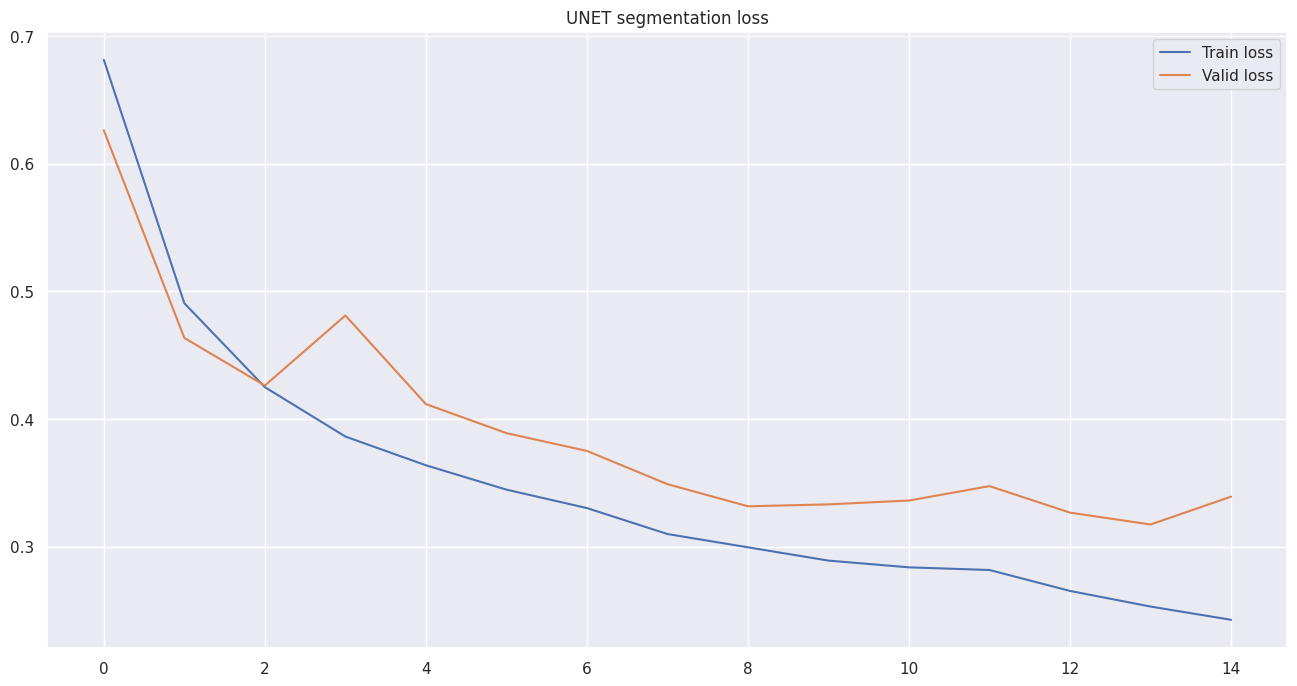

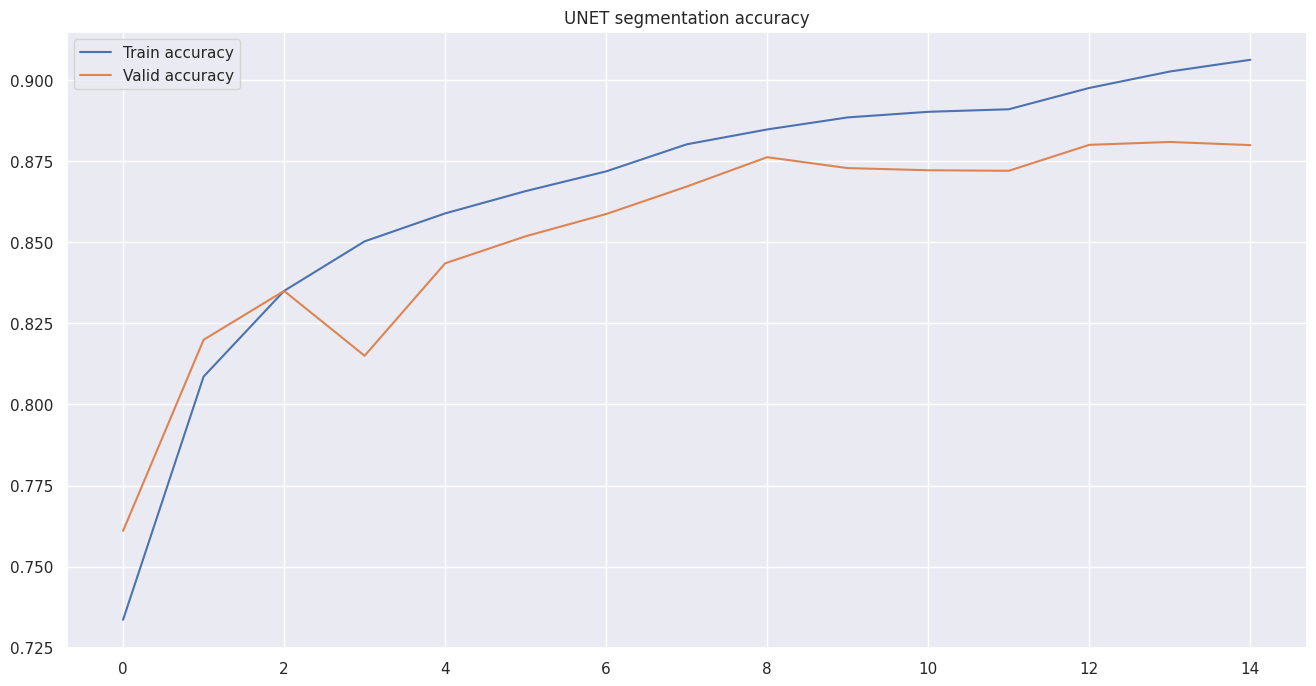

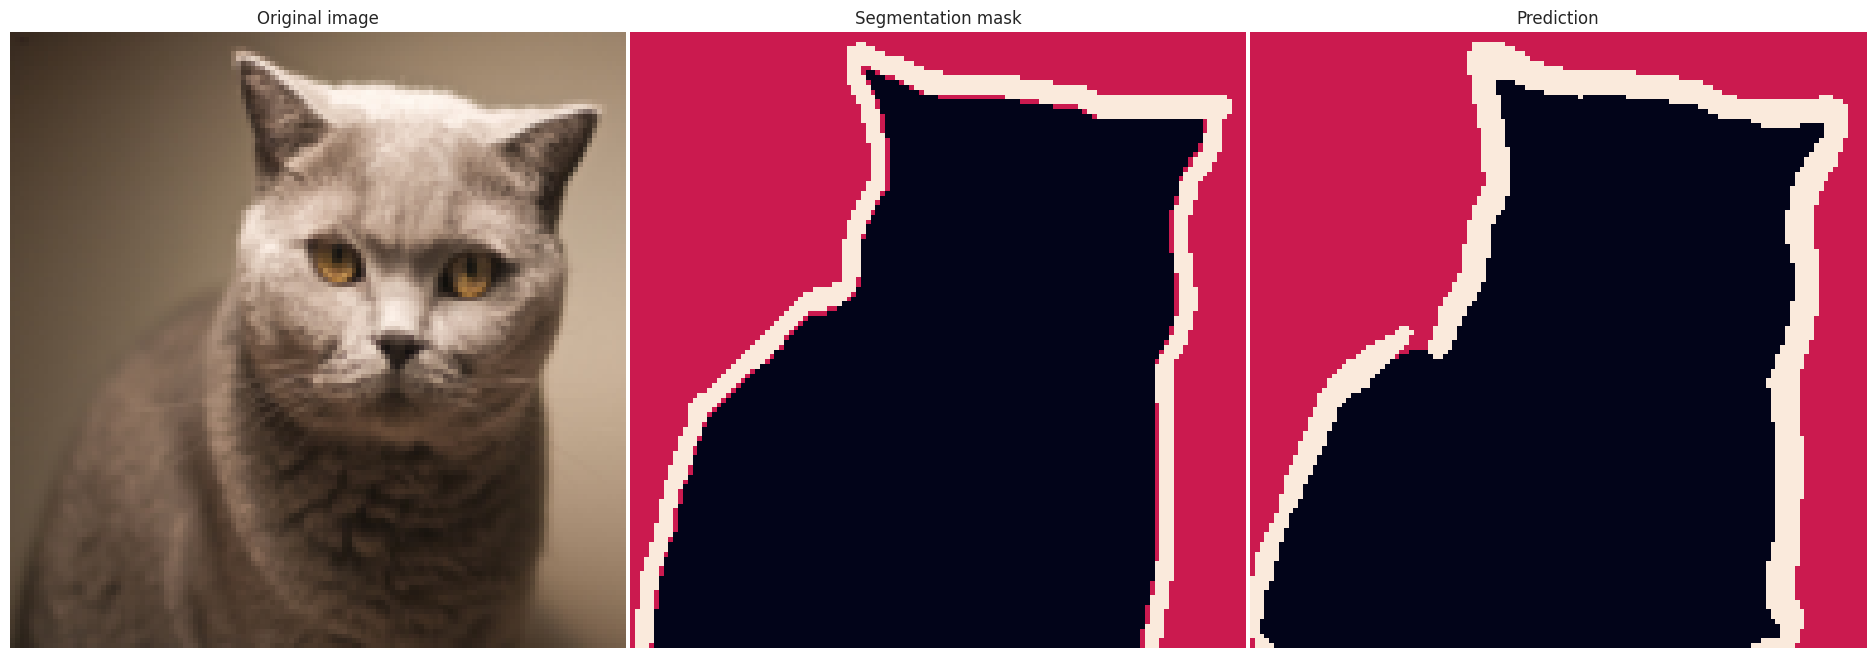

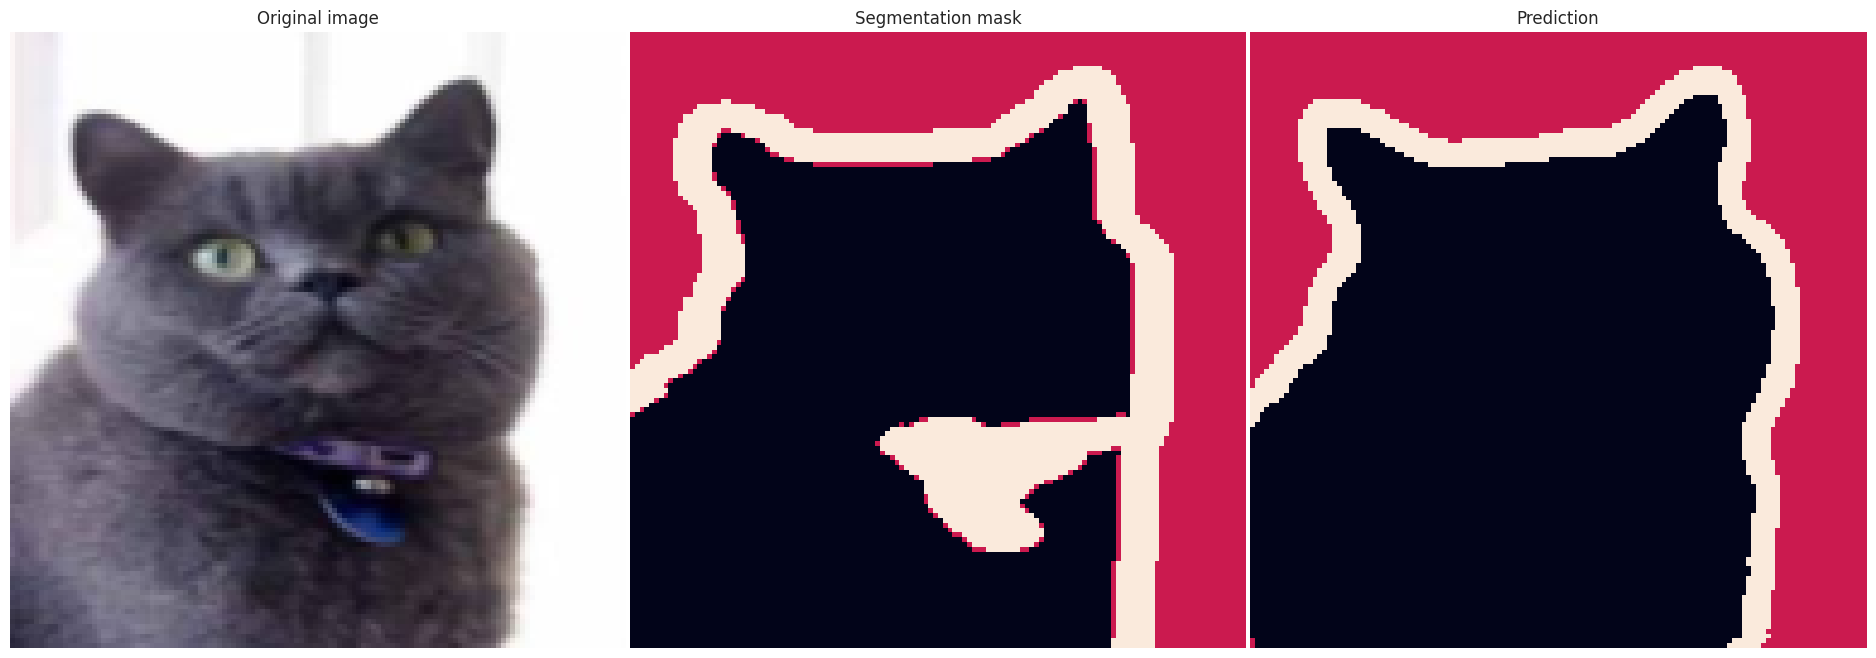

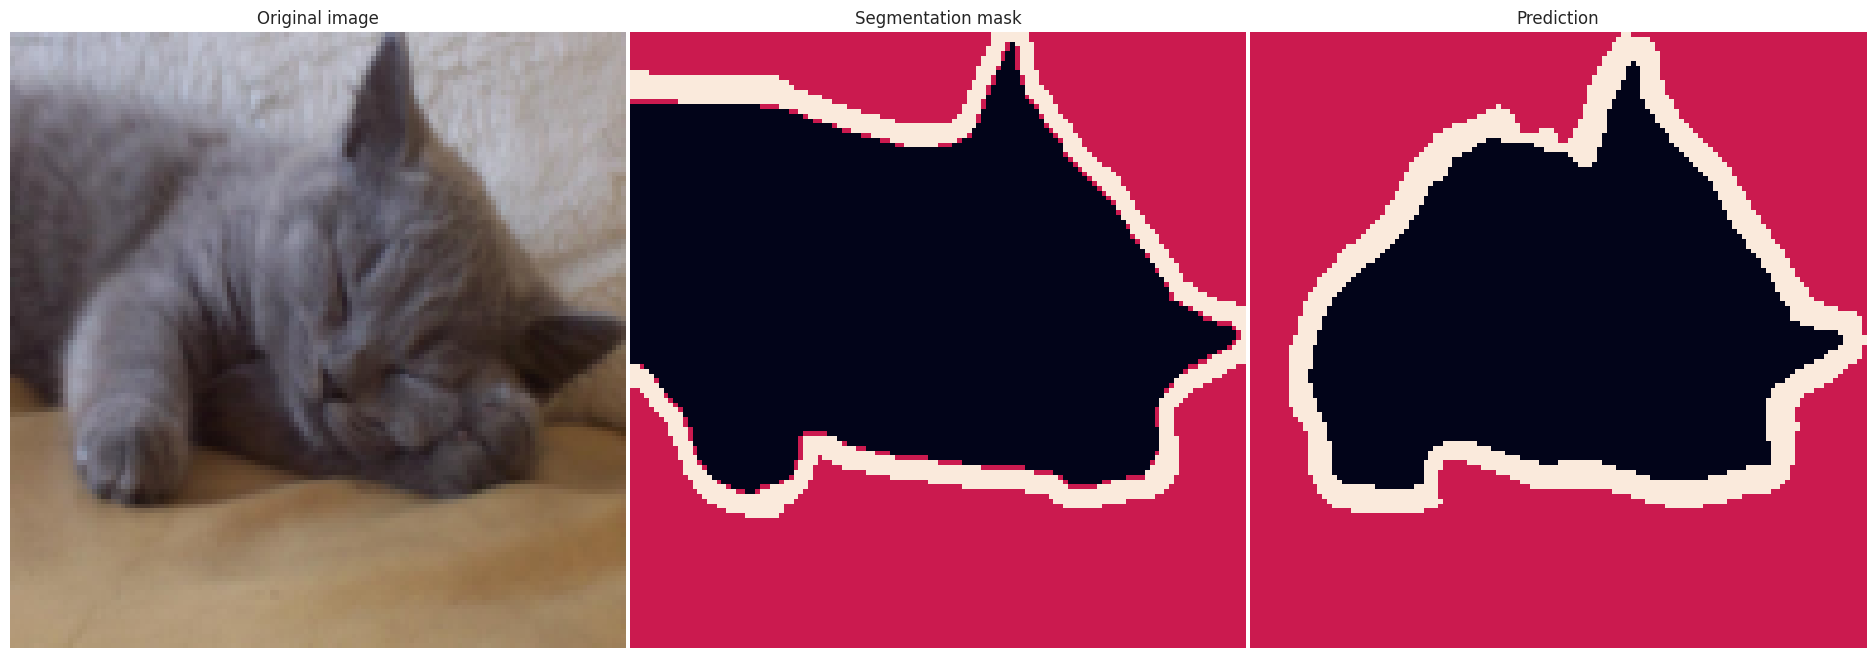

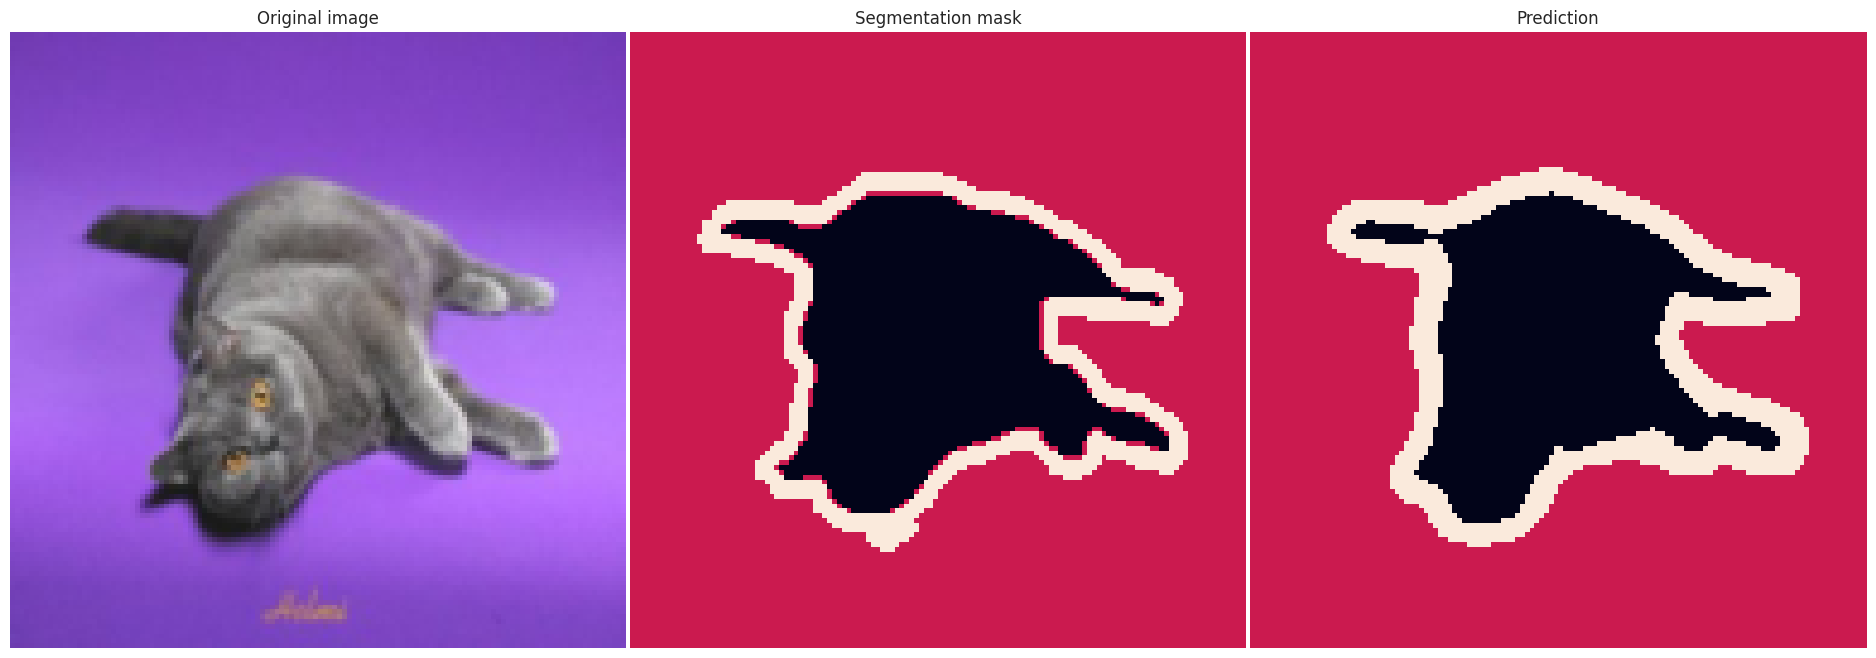

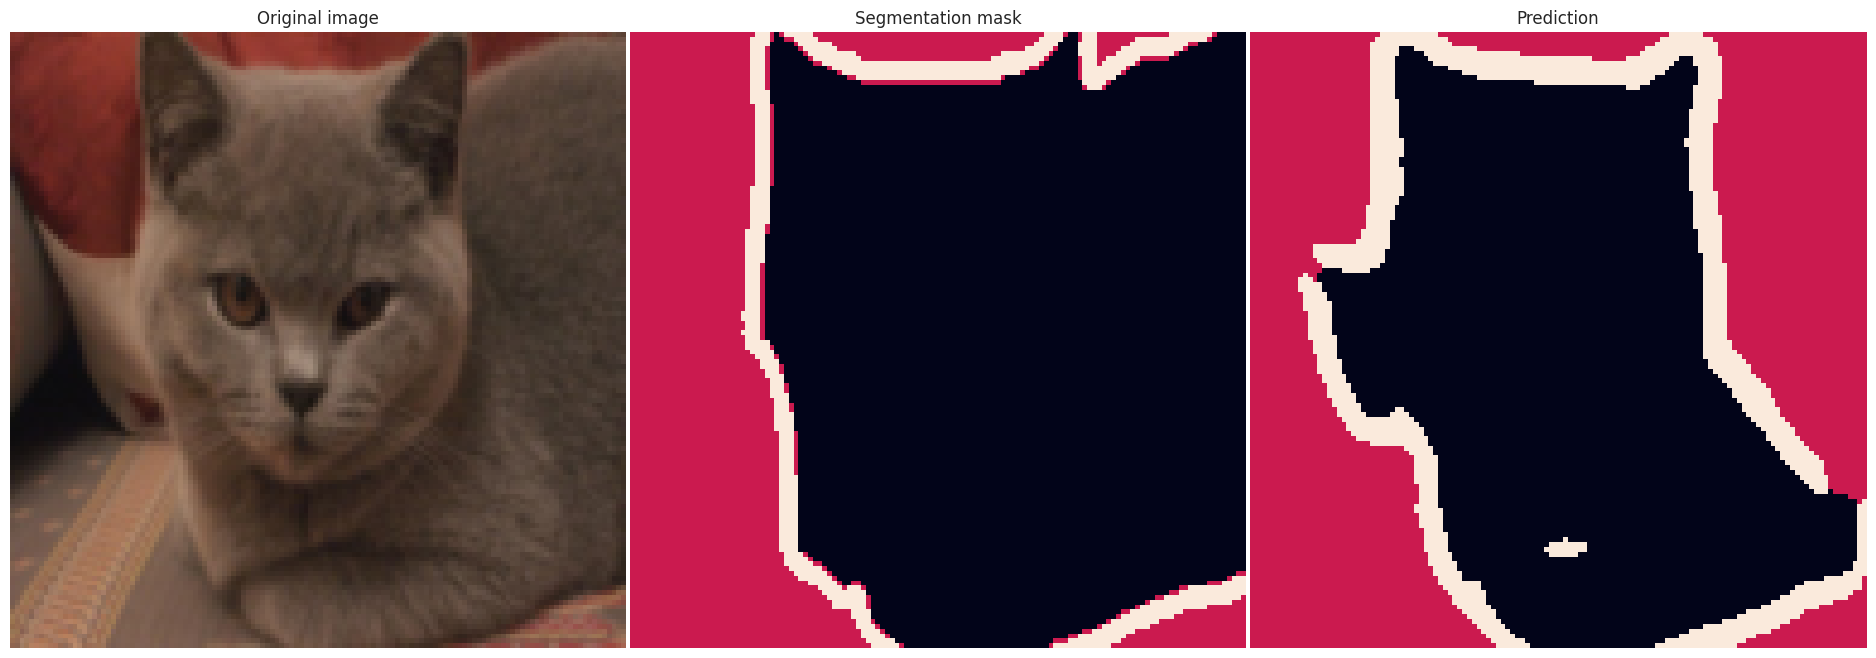

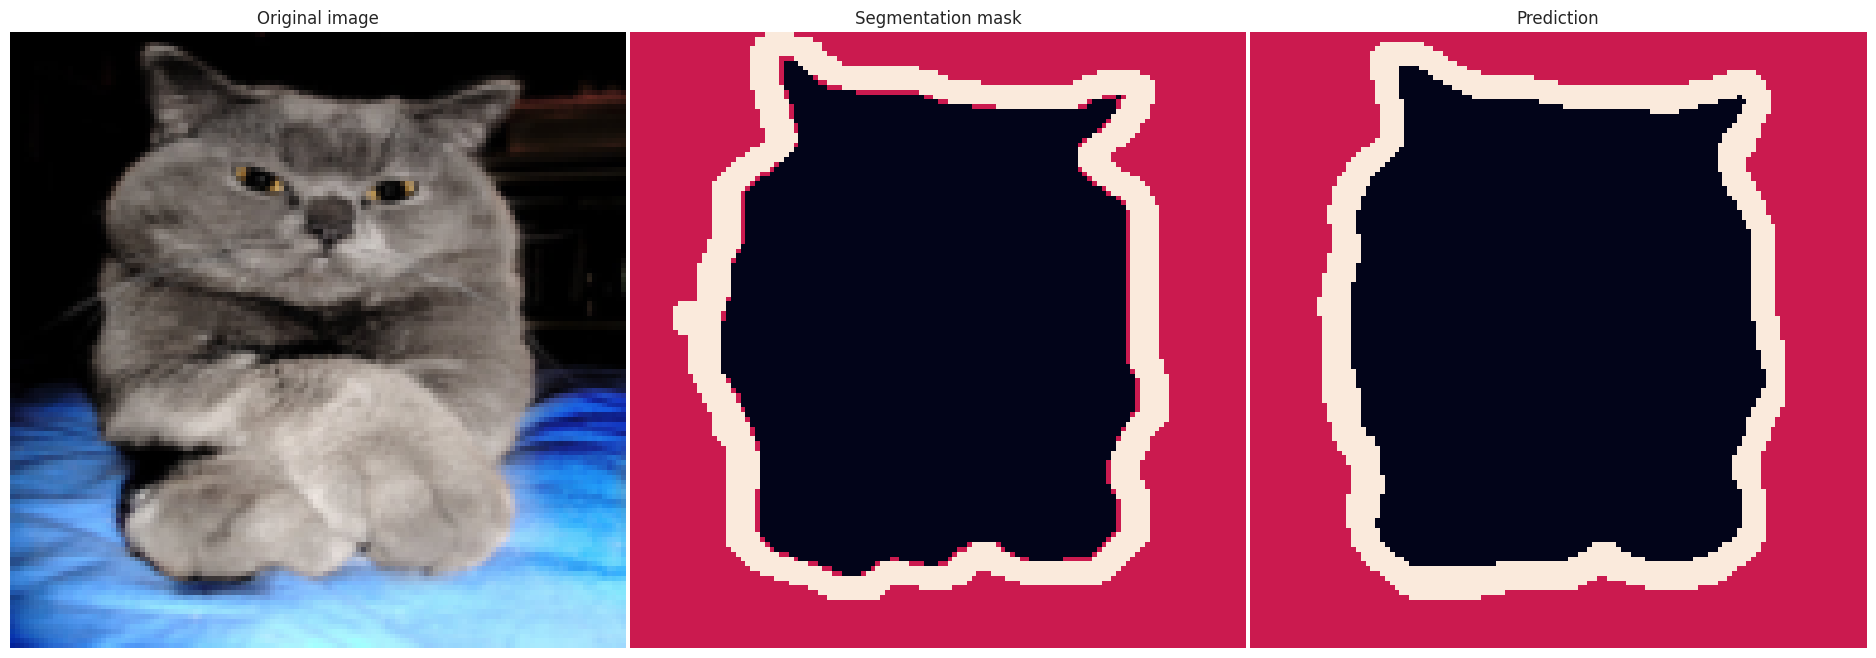

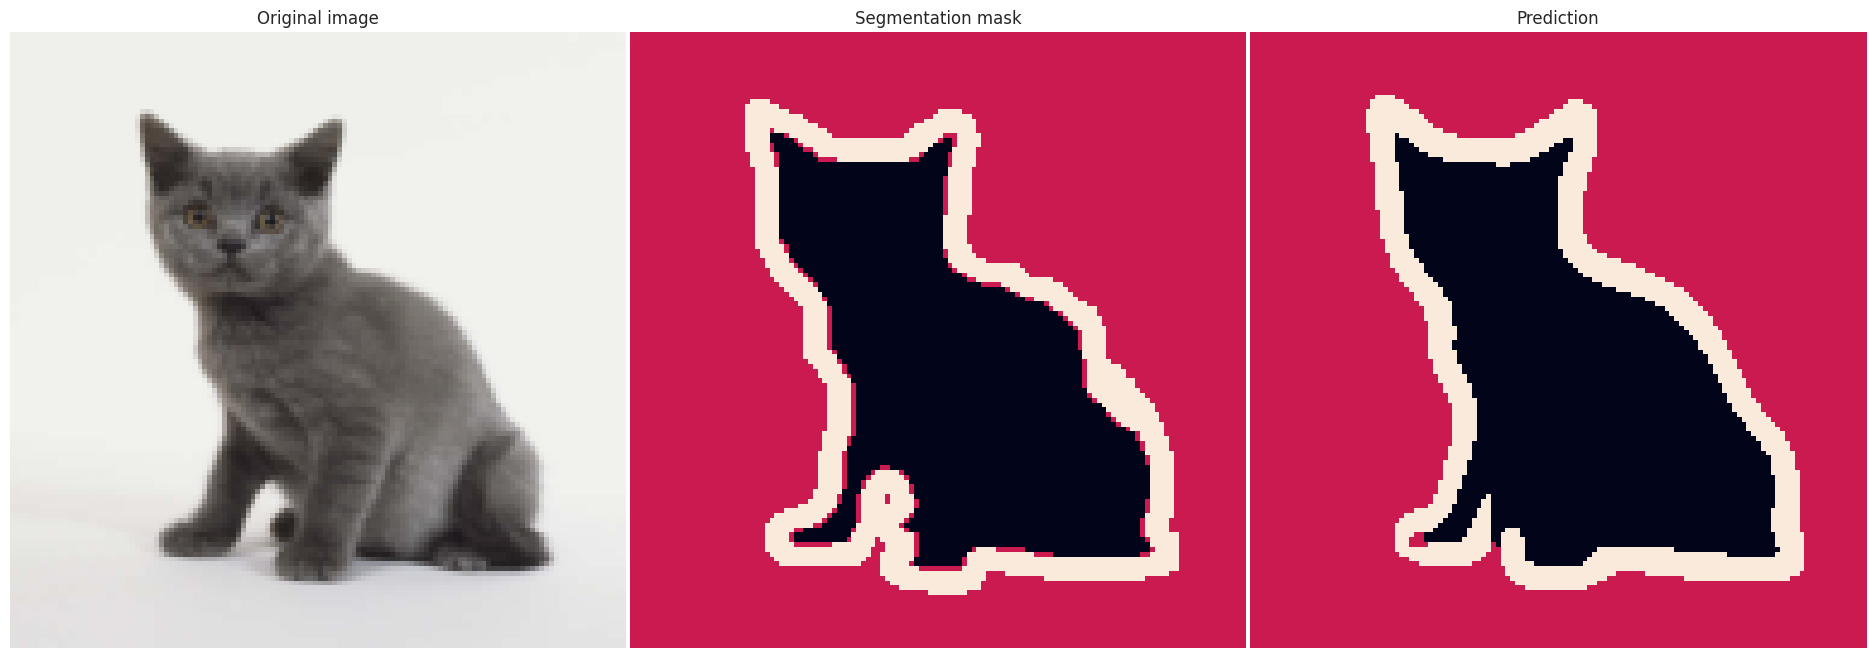

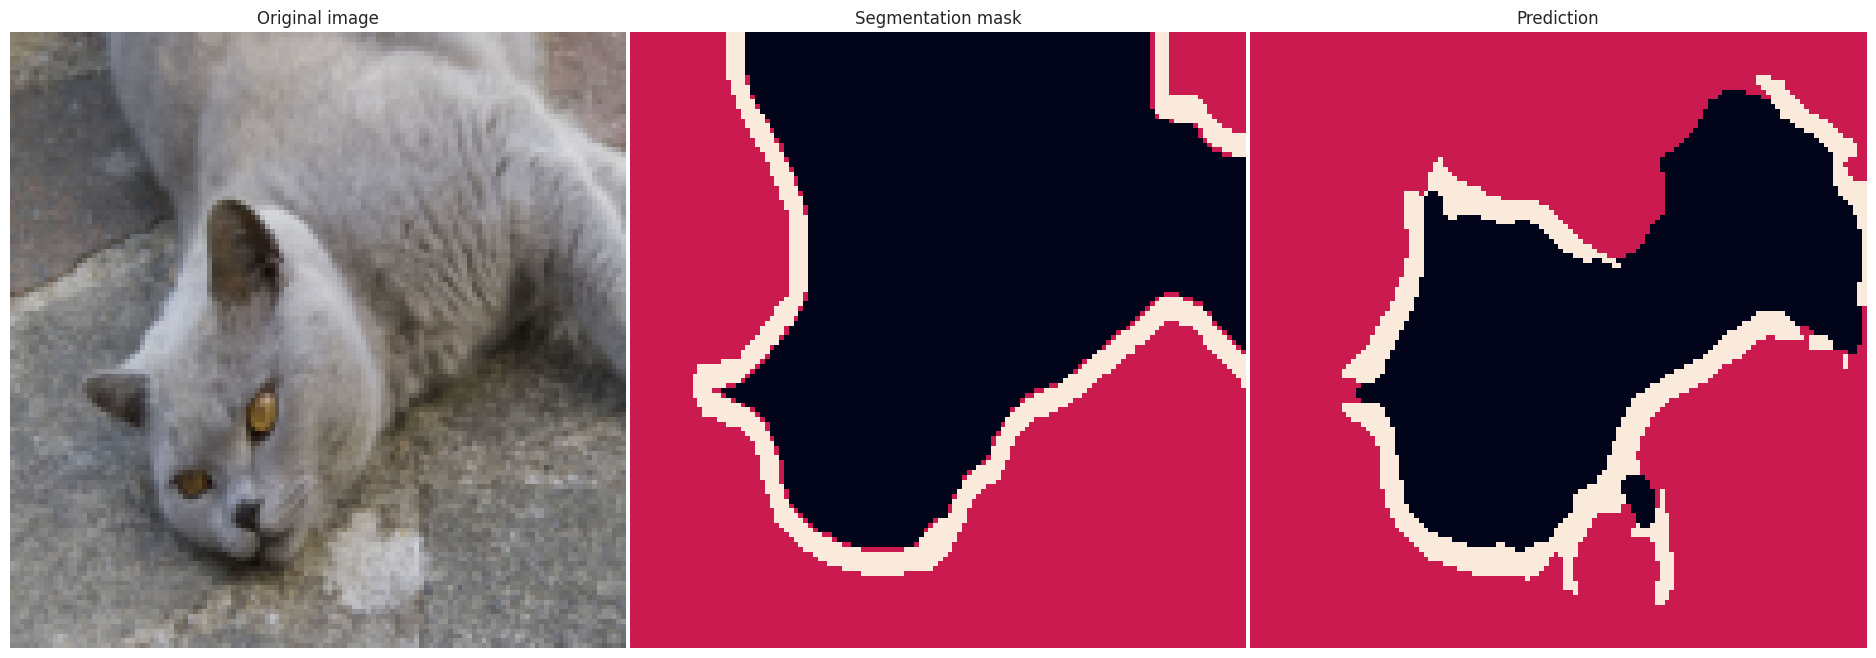

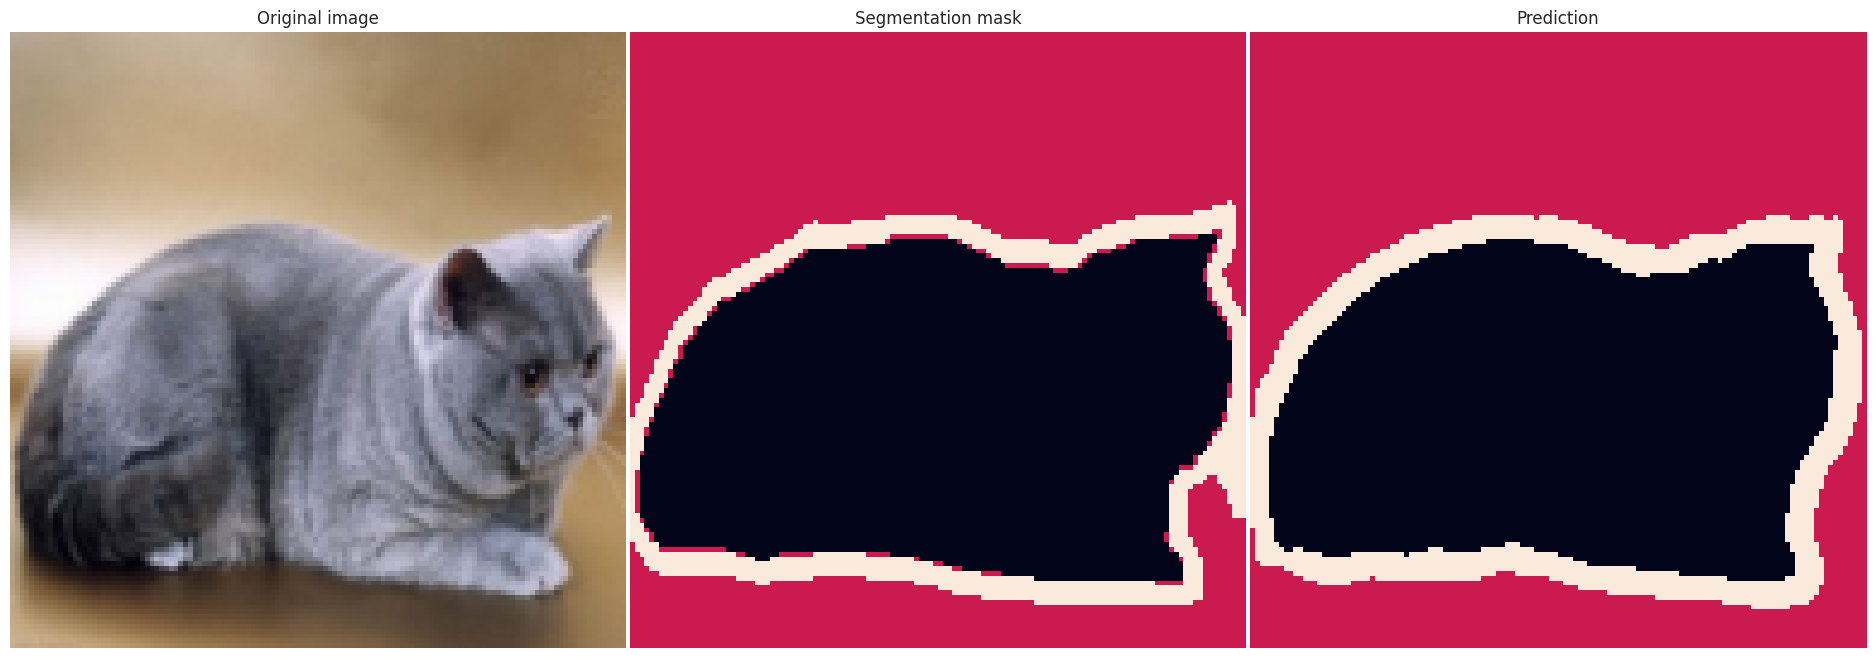

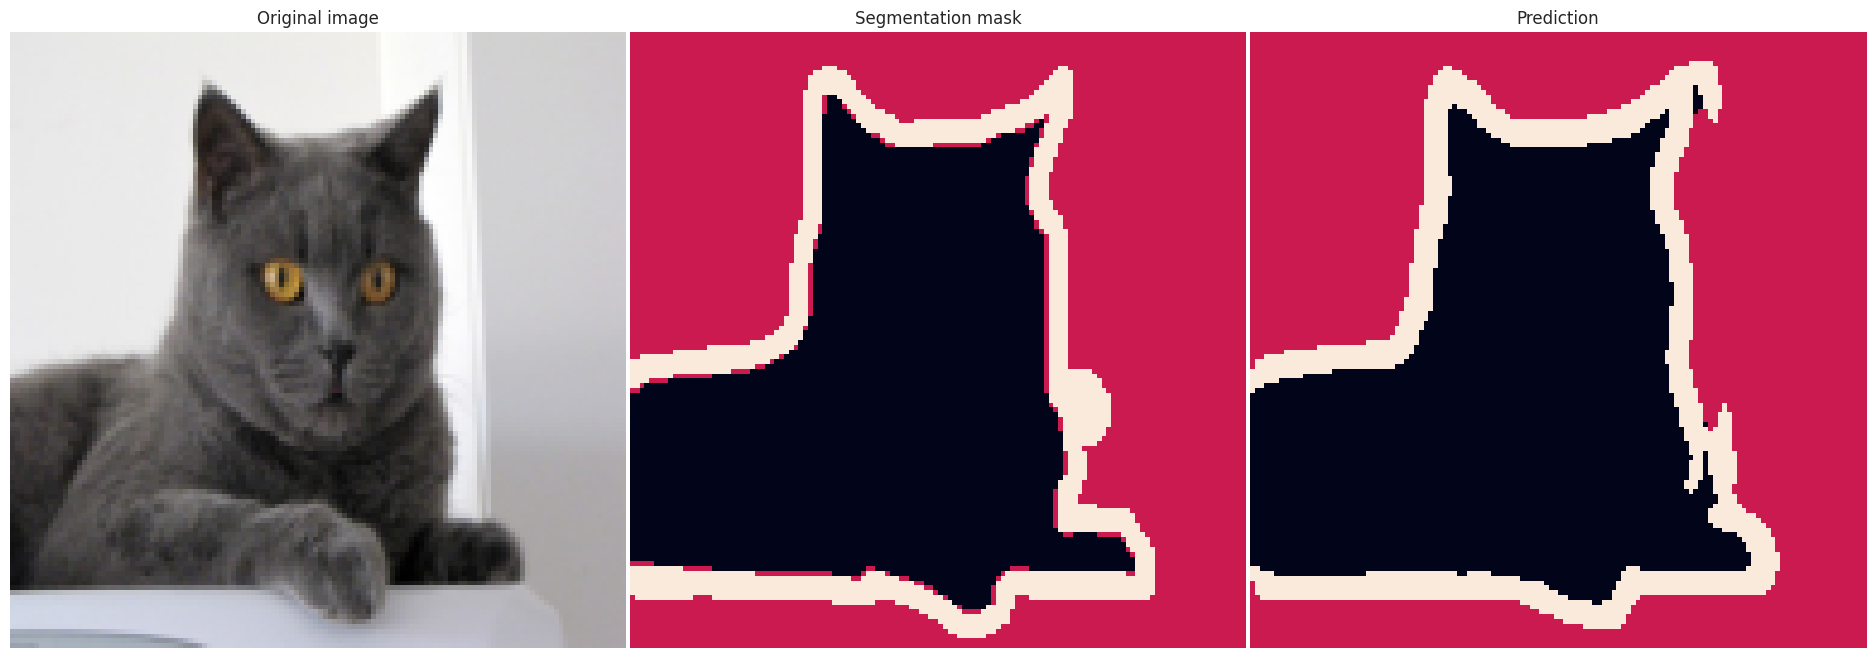

In [ ]:
# Импортируем оптимизатор Adam (адаптивный метод градиентного спуска)
from torch.optim import Adam

# Создаем экземпляр модели U-Net и сразу переносим все ее веса и буферы на видеокарту (device)
model = UNET().to(device)

# Инициализируем оптимизатор Adam, передавая ему все обучаемые параметры модели
# lr=1e-3 (0.001) — стандартная начальная скорость обучения (learning rate)
optimizer = Adam(model.parameters(), lr=1e-3)

# Запускаем полный цикл обучения модели на 15 эпох с визуализацией графиков и масок
fit(model, train_loader, valid_loader, optimizer, loss_fn, device, 15, 'UNET segmentation')

In [ ]:
# Импортируем класс датасета VOCDetection из модуля torchvision.datasets
from torchvision.datasets import VOCDetection

# Создаем объект датасета:
# 'voc' — путь к папке на диске, куда будут сохранены данные
# download=True — автоматически скачать архив с датасетом из интернета, если его еще нет в папке 'voc'
dataset = VOCDetection('voc', download=True)

In [ ]:
len(dataset)

In [ ]:
dataset[0]

In [ ]:
dataset[0][0]

In [ ]:
# Создаем пустой список для накопления названий всех объектов из всех картинок
target_names = []

# Проходим по каждому элементу датасета.
# obj — это кортеж (image, target_dict), поэтому obj[1] — это словарь с разметкой
for obj in dataset:
    # Извлекаем список всех объектов на картинке: obj[1]['annotation']['object']
    # С помощью генератора списка берем у каждого объекта значение по ключу 'name'
    # Метод .extend() добавляет все найденные имена в общий список target_names
    target_names.extend([x['name'] for x in obj[1]['annotation']['object']])

# Превращаем список во множество set(), чтобы удалить дубликаты, и возвращаем обратно в list
target_names = list(set(target_names))

In [ ]:
# Создаем словарь для перевода названия класса в числовой индекс (например, {'person': 0, ...})
# Используется при подготовке целевых меток (targets) для обучения нейросети
target2idx = {name: i for i, name in enumerate(target_names)}

# Создаем обратный словарь для перевода предсказанного числа обратно в название (например, {0: 'person', ...})
# Используется для интерпретации и отрисовки предсказаний модели
idx2target = {i: name for i, name in enumerate(target_names)}

# Выводим оба словаря в Jupyter Notebook для визуальной проверки
target2idx, idx2target

In [ ]:
# На скриншоте представлена функция target_transform, которая преобразует исходную XML-разметку датасета
# Pascal VOC в стандартный формат словаря тензоров PyTorch (boxes и labels),
# необходимый для обучения моделей детекции.

def target_transform(voc_target):
    # Создаем пустой словарь для хранения отформатированной разметки одной картинки
    target = {}

    # Формируем тензор с координатами ограничивающих рамок (bounding boxes)
    # Формат координат: [xmin, ymin, xmax, ymax] с типом float32
    # Итоговая размерность тензора: [N, 4], где N — количество объектов на картинке
    target['boxes'] = torch.tensor(
        [
            [
                float(x['bndbox']['xmin']),
                float(x['bndbox']['ymin']),
                float(x['bndbox']['xmax']),
                float(x['bndbox']['ymax'])
            ] for x in voc_target['annotation']['object']
        ],
        dtype=torch.float32
    )

    # Формируем тензор с числовыми индексами классов для каждого объекта
    # Тип int64 (LongTensor) обязателен для функций потерь в PyTorch
    # Итоговая размерность тензора: [N]
    target['labels'] = torch.tensor(
        [target2idx[x['name']] for x in voc_target['annotation']['object']],
        dtype=torch.int64
    )

    return target

In [ ]:
# На скриншоте показан тестовый вызов функции target_transform для разметки первого элемента датасета (dataset[0][1]) и результат её работы в виде словаря тензоров.

# Вызываем функцию преобразования для словаря аннотации первого изображения
# dataset[0] возвращает кортеж (image, annotation_dict), поэтому берем индекс [1]
target_transform(dataset[0][1])

# Вывод ячейки (результат работы функции):
# {'boxes': tensor([[ 53.,  87., 471., 420.],
#                   [158.,  44., 289., 167.]]),
#  'labels': tensor([ 0, 19])}


# Что означают эти числа
# • boxes (тензор размерностью [2, 4]): На первой картинке обнаружено 2 объекта.
# Первая строка [53., 87., 471., 420.] задает координаты [xmin, ymin, xmax, ymax] первого объекта в пикселях, а вторая строка [158., 44., 289., 167.] — координаты второго объекта.
# • labels (тензор размерностью [2]): Указывает числовые индексы классов для этих двух рамок.
# Первый объект получил класс с индексом 0, а второй — с индексом 19 (всего классов в VOC 20, поэтому индексы лежат в диапазоне от 0 до 19).


In [ ]:
# ==============================================================================
# ШАГ: Визуализация изображений и ограничивающих рамок (Bounding Boxes)
# ------------------------------------------------------------------------------
# После того как мы научились превращать сырую XML-разметку в тензоры координат
# и классов (функция target_transform), нам нужен инструмент для визуальной
# проверки данных. Здесь мы используем встроенную утилиту draw_bounding_boxes
# из torchvision, чтобы рисовать красные рамки с подписями прямо на тензоре
# картинки и выводить результат через Matplotlib без лишних осей координат.
# ==============================================================================

from torchvision.utils import draw_bounding_boxes


def show(imgs):
    # Конвертер для перевода тензора обратно в формат картинки PIL
    to_pil = T.ToPILImage()

    # Если передана одна картинка, оборачиваем ее в список для единообразного цикла
    if not isinstance(imgs, list):
        imgs = [imgs]

    # Создаем сетку графиков в одну строку по числу переданных изображений
    fix, axs = plt.subplots(ncols=len(imgs), squeeze=False, figsize=(16, 8))

    for i, img in enumerate(imgs):
        # Отключаем отслеживание градиентов и переводим тензор в PIL Image
        img = img.detach()
        img = to_pil(img)

        # Отрисовываем картинку в соответствующей ячейке и убираем деления по осям
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])


def draw_boxes_single_image(image, boxes, labels):
    # Задаем красный цвет для каждой рамки на изображении
    colors = ["red" for _ in boxes]

    # Накладываем рамки с толщиной линий 5 пикселей на тензор image и выводим на экран
    show(draw_bounding_boxes(image, boxes, labels, colors=colors, width=5))


In [ ]:
# ==============================================================================
# ШАГ: Проверка пайплайна на первом примере из датасета
# ------------------------------------------------------------------------------
# Здесь мы собираем все созданные ранее компоненты вместе, чтобы визуально
# убедиться в правильности разметки:
# 1. Берем первую картинку dataset[0][0] и переводим ее в тензор через
#    PILToTensor() (он сохраняет тип uint8 и диапазон 0..255, в отличие от ToTensor).
# 2. Пропускаем сырую аннотацию dataset[0][1] через нашу функцию target_transform
#    и забираем координаты рамок по ключу 'boxes'.
# 3. Числовые метки из 'labels' переводим обратно в читаемые названия классов
#    с помощью словаря idx2target и передаем все в draw_boxes_single_image.
# ==============================================================================

draw_boxes_single_image(
    T.PILToTensor()(dataset[0][0]),
    target_transform(dataset[0][1])['boxes'],
    [idx2target[label.item()] for label in target_transform(dataset[0][1])['labels']]
)


In [ ]:
# ==============================================================================
# ШАГ: Пакетная визуальная проверка нескольких примеров из датасета
# ------------------------------------------------------------------------------
# Проверив пайплайн на нулевой картинке, мы прогоняем в цикле изображения
# с 1-го по 9-е (range(1, 10)). Для каждого элемента извлекаем саму картинку
# (dataset[i][0]) и ее разметку (dataset[i][1]), преобразуем разметку в тензоры
# через target_transform и выводим на экран с наложенными рамками и названиями
# классов, чтобы убедиться в корректности парсинга на разных примерах.
# ==============================================================================

for i in range(1, 10):
    draw_boxes_single_image(
        T.PILToTensor()(dataset[i][0]),
        target_transform(dataset[i][1])['boxes'],
        [idx2target[label.item()] for label in target_transform(dataset[i][1])['labels']]
    )


In [ ]:
# ==============================================================================
# ШАГ: Создание датасетов и загрузчиков данных (DataLoader) для детекции
# ------------------------------------------------------------------------------
# В задаче детекции картинки имеют разный размер и разное количество объектов,
# поэтому стандартный DataLoader не может склеить их в один прямоугольный тензор
# (выдаст ошибку). Чтобы решить эту проблему, мы пишем функцию collate_fn,
# которая собирает батч в виде двух отдельных кортежей: кортежа картинок и
# кортежа словарей разметки. После этого мы создаем обучающий (train) и
# валидационный (val) датасеты, сразу подключая к ним конвертацию картинок
# в тензоры (T.ToTensor) и нашу функцию парсинга разметки (target_transform).
# ==============================================================================

def collate_fn(batch):
    # Распаковываем список пар [(img1, target1), (img2, target2), ...]
    # в кортеж из двух кортежей: ((img1, img2, ...), (target1, target2, ...))
    return tuple(zip(*batch))


# Инициализируем обучающую выборку Pascal VOC
train_dataset = VOCDetection(
    '../datasets/voc',                 # Путь к локальной папке с датасетом
    image_set='train',                 # Берем только обучающую часть
    transform=T.ToTensor(),            # Переводим PIL-картинки в тензоры float32 (диапазон 0..1)
    target_transform=target_transform  # Подключаем нашу функцию преобразования XML в тензоры
)

# Инициализируем валидационную выборку Pascal VOC
valid_dataset = VOCDetection(
    '../datasets/voc',
    image_set='val',                   # Берем только валидационную часть
    transform=T.ToTensor(),
    target_transform=target_transform
)

# Создаем загрузчики батчей с размером батча 4 и нашей кастомной функцией сборки collate_fn
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=8, pin_memory=True, collate_fn=collate_fn)
valid_loader = DataLoader(valid_dataset, batch_size=4, shuffle=False, num_workers=8, pin_memory=True, collate_fn=collate_fn)


In [ ]:
# ==============================================================================
# ШАГ: Загрузка предобученной модели Faster R-CNN и адаптация под наши классы
# ------------------------------------------------------------------------------
# Обучать детектор с нуля долго и дорого, поэтому мы применяем Transfer Learning.
# Мы скачиваем архитектуру Faster R-CNN (версии v2 на базе ResNet-50 + FPN),
# уже обученную на 80 классах большого датасета COCO. Затем мы замораживаем все
# ее веса (requires_grad_(False)), чтобы сохранить умение находить общие признаки
# объектов, и заменяем финальный слой предсказания (box_predictor) на новый,
# настроенный под количество наших классов (len(target_names)). У нового слоя
# градиенты включены по умолчанию, поэтому обучаться будет только он.
# ==============================================================================

from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def get_detection_model():
    # Загружаем модель с весами, предобученными на COCO
    model = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1)

    # Замораживаем все слои сети (отключаем подсчет градиентов для базовой части)
    model.requires_grad_(False)

    # Заменяем финальную голову (box_predictor) на новую с выходом под наше число классов
    # 1024 — размер входного вектора признаков от предыдущего слоя (in_features)
    model.roi_heads.box_predictor = FastRCNNPredictor(1024, len(target_names))

    return model

# Создаем экземпляр адаптированной модели
model = get_detection_model()